In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('Finalized_MasterList.csv')

#### Removing Columns that Have Duplicate Entries ####

In [3]:
drop_cols = ['Life expectancy at birth, female (years) [SP.DYN.LE00.FE.IN]',
             'Life expectancy at birth, male (years) [SP.DYN.LE00.MA.IN]',
             'Life expectancy at birth, total (years) [SP.DYN.LE00.IN]',
             'Adolescent fertility rate (births per 1,000 women ages 15-19) [SP.ADO.TFRT]',
             'Labor force participation rate for ages 15-24, female (%) (modeled ILO estimate) [SL.TLF.ACTI.1524.FE.ZS]',
             'Labor force participation rate for ages 15-24, male (%) (modeled ILO estimate) [SL.TLF.ACTI.1524.MA.ZS]',
             'Labor force participation rate for ages 15-24, total (%) (modeled ILO estimate) [SL.TLF.ACTI.1524.ZS]',
             'Labor force participation rate, female (% of female population ages 15+) (modeled ILO estimate) [SL.TLF.CACT.FE.ZS]',
             'Labor force participation rate, male (% of male population ages 15+) (modeled ILO estimate) [SL.TLF.CACT.MA.ZS]',
             'Labor force participation rate, total (% of total population ages 15+) (modeled ILO estimate) [SL.TLF.CACT.ZS]',
             'Labor force, total [SL.TLF.TOTL.IN]',
             'Labour force participation rate, female (% ages 15 and older)',
             'Labour force participation rate, male (% ages 15 and older)']

In [4]:
df = df.drop(columns= drop_cols)

#### Creating Scatterplots of all variables with correlation above .7 ####

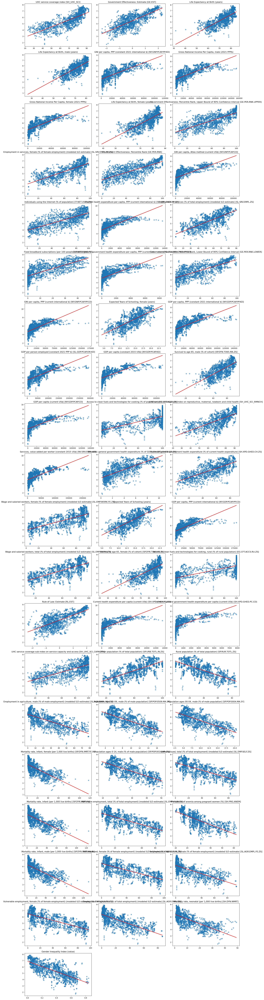

In [5]:
import matplotlib.pyplot as plt
import numpy as np

corr = (
    df[df['year'] <= 2022]
    .drop(columns=["country", "year"])
    .corr()["Life evaluation (3-year average)"]
    .sort_values(ascending=False)
)


top_vars = corr.drop(["Life evaluation (3-year average)", "Rank"])
top_vars = top_vars[top_vars.abs() > 0.7].index

y = df["Life evaluation (3-year average)"]

cols = list(top_vars)
n = len(cols)

ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 4*nrows))
axes = axes.flatten()

for i, col in enumerate(cols):
    ax = axes[i]
    x = df[col]
    mask = x.notna() & y.notna()
    x_clean = x[mask]
    y_clean = y[mask]

    m, b = np.polyfit(x_clean, y_clean, 1)
    x_line = np.linspace(x_clean.min(), x_clean.max(), 100)
    y_line = m * x_line + b

    ax.scatter(x_clean, y_clean, alpha=0.5)
    ax.plot(x_line, y_line, color="red", linewidth=2)

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

# Remove unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### Displaying Distributions of Features With Correlation Above .7 ####

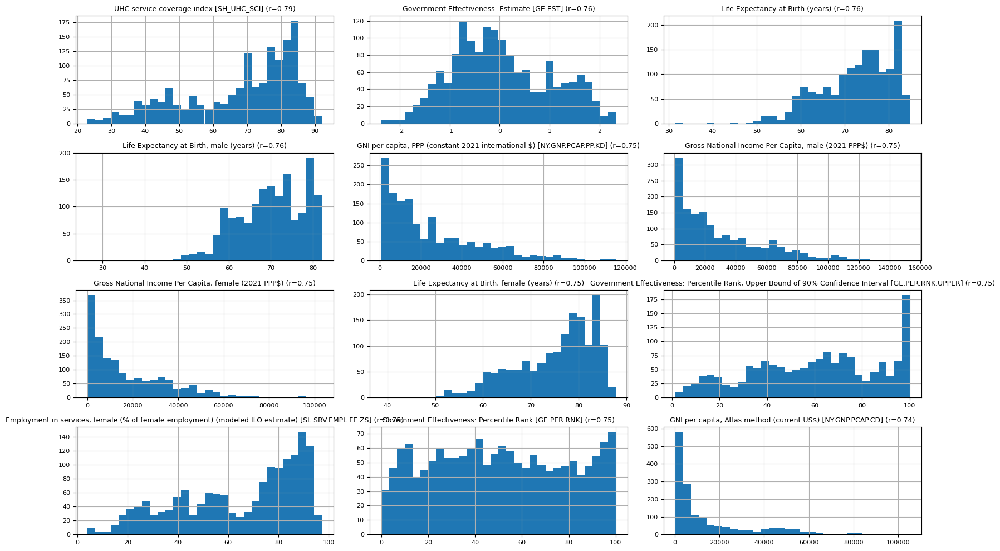

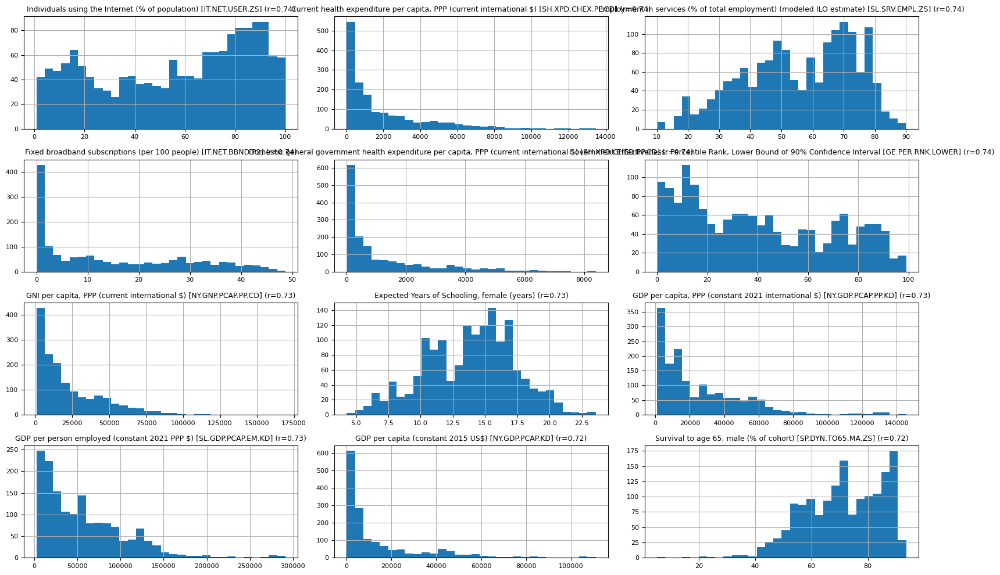

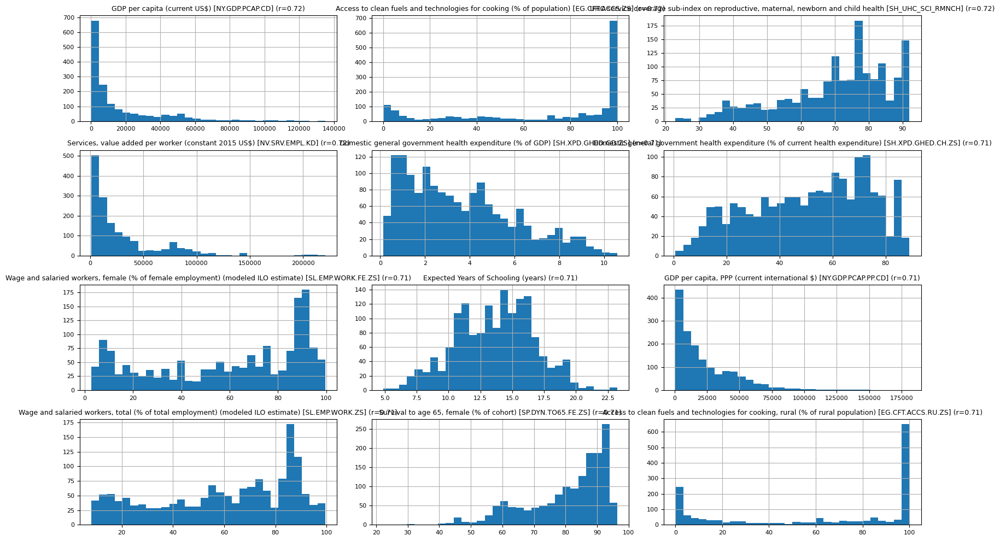

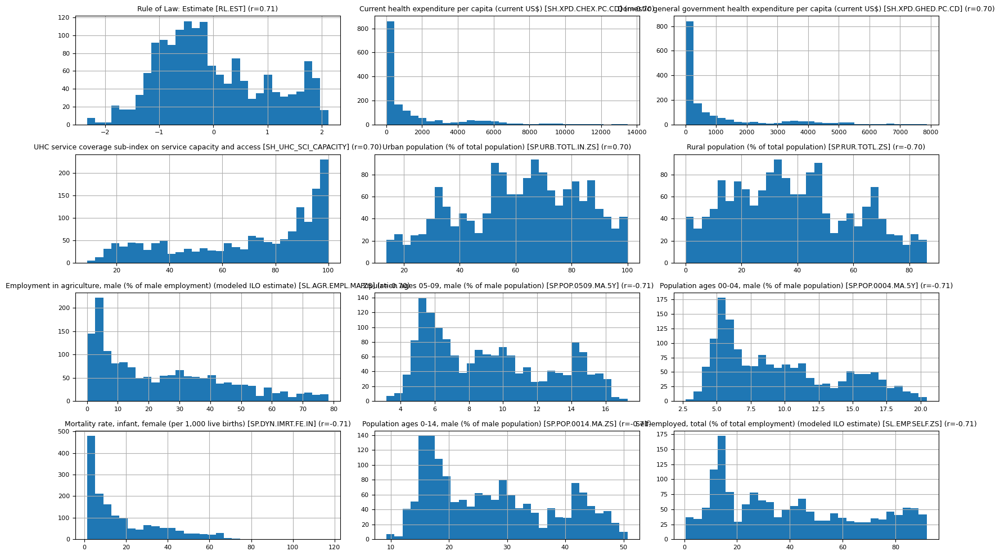

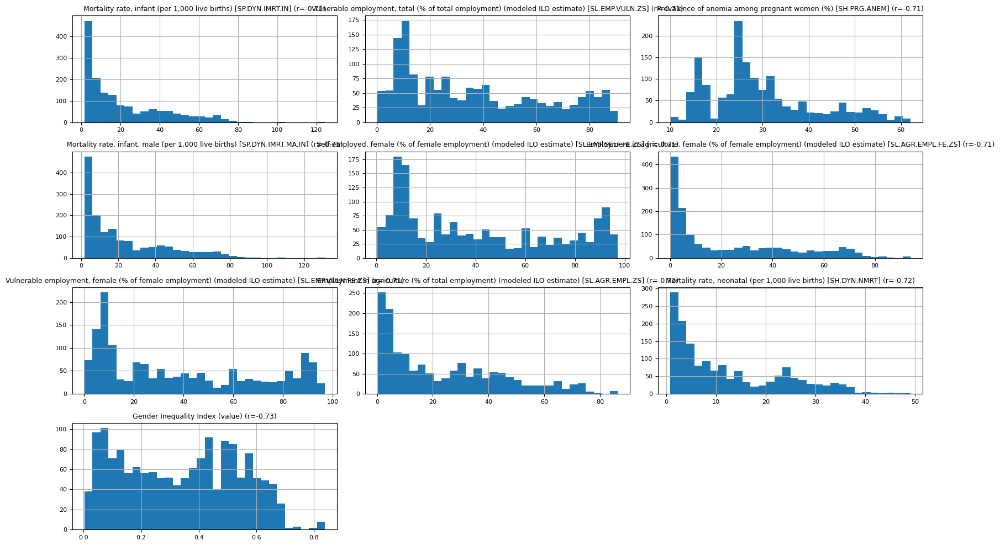

In [6]:
plots_per_page = 12
ncols = 3
nrows = 4

cols = list(top_vars)

# 3. Generate Histograms
for page_start in range(0, len(cols), plots_per_page):
    page_cols = cols[page_start:page_start + plots_per_page]
    
    # Calculate actual rows needed for this page (in case it's the last page)
    current_rows = (len(page_cols) + ncols - 1) // ncols
    
    axes = df[page_cols].hist(
        bins=30,
        figsize=(16, current_rows * 2.5), # Dynamic height
        layout=(current_rows, ncols)
    )

    for ax in plt.gcf().axes:
        ax.set_xlabel("")                   
        ax.tick_params(axis="both", labelsize=8)
        # Added the correlation value to the title for clarity
        title = ax.get_title()
        if title in corr:
            ax.set_title(f"{title} (r={corr[title]:.2f})", fontsize=9)

    plt.tight_layout()
    plt.show()

#### Displaying Distribution of Life Evaluation (Target Variable) ####

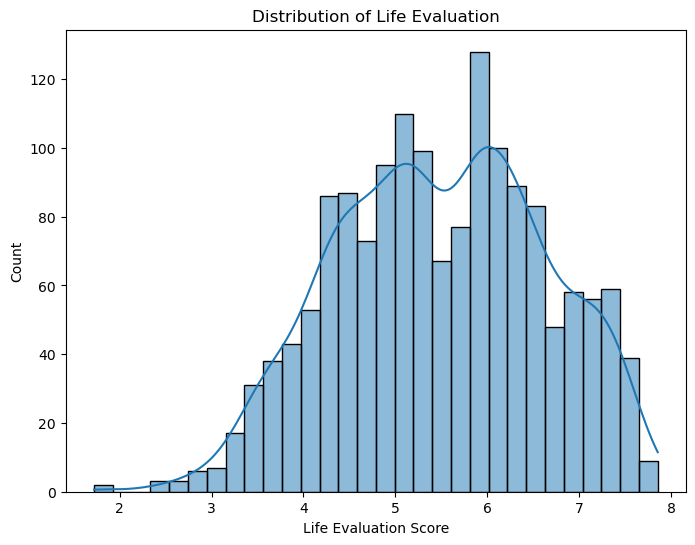

In [7]:
import seaborn as sns
plt.figure(figsize=(8,6))

sns.histplot(
    data=df,
    x="Life evaluation (3-year average)",
    bins=30,
    kde=True
)

plt.title("Distribution of Life Evaluation")
plt.xlabel("Life Evaluation Score")
plt.ylabel("Count")

plt.show()

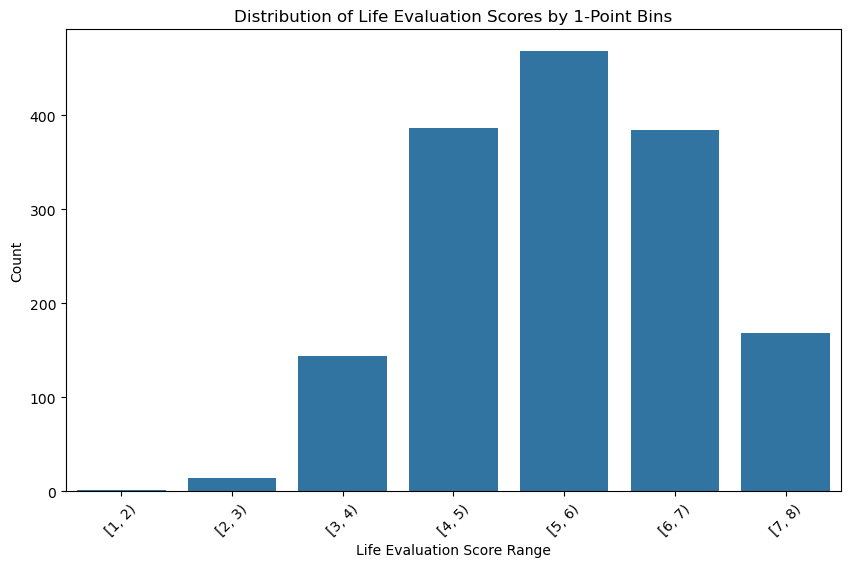

In [8]:
import numpy as np

values = df["Life evaluation (3-year average)"].dropna()


bins = np.arange(0, 11, 1)

df["score_bin"] = pd.cut(
    df["Life evaluation (3-year average)"],
    bins=bins,
    right=False  
)


plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x="score_bin",
    order=sorted(df["score_bin"].dropna().unique())
)

plt.xticks(rotation=45)
plt.xlabel("Life Evaluation Score Range")
plt.ylabel("Count")
plt.title("Distribution of Life Evaluation Scores by 1-Point Bins")

plt.show()

#### Creating a new Data Frame that contains only the highest correlated variables ####

In [9]:
new_cols = top_vars.tolist()
new_cols.append('year')
new_cols.append('Life evaluation (3-year average)')

In [10]:
df_top_corr = df[new_cols]
df_top_corr.head()

,UHC service coverage index [SH_UHC_SCI],Government Effectiveness: Estimate [GE.EST],Life Expectancy at Birth (years),"Life Expectancy at Birth, male (years)","GNI per capita, PPP (constant 2021 international $) [NY.GNP.PCAP.PP.KD]","Gross National Income Per Capita, male (2021 PPP$)","Gross National Income Per Capita, female (2021 PPP$)","Life Expectancy at Birth, female (years)","Government Effectiveness: Percentile Rank, Upper Bound of 90% Confidence Interval [GE.PER.RNK.UPPER]","Employment in services, female (% of female employment) (modeled ILO estimate) [SL.SRV.EMPL.FE.ZS]",...,Prevalence of anemia among pregnant women (%) [SH.PRG.ANEM],"Mortality rate, infant, male (per 1,000 live births) [SP.DYN.IMRT.MA.IN]","Self-employed, female (% of female employment) (modeled ILO estimate) [SL.EMP.SELF.FE.ZS]","Employment in agriculture, female (% of female employment) (modeled ILO estimate) [SL.AGR.EMPL.FE.ZS]","Vulnerable employment, female (% of female employment) (modeled ILO estimate) [SL.EMP.VULN.FE.ZS]",Employment in agriculture (% of total employment) (modeled ILO estimate) [SL.AGR.EMPL.ZS],"Mortality rate, neonatal (per 1,000 live births) [SH.DYN.NMRT]",Gender Inequality Index (value),year,Life evaluation (3-year average)
0,36.0,-1.474100,61.250,59.625,2817.996022,4719.872,1140.727,62.852,13.270143,22.180634,...,34.0,77.9,96.625876,51.827902,96.615626,51.317493,46.8,0.716,2011,4.258
1,37.0,-1.375535,61.735,60.099,2817.996022,5366.294,885.649,63.344,15.165876,21.002022,...,33.7,75.1,96.010431,49.285217,95.998021,48.764168,45.5,0.731,2012,4.040
2,38.0,-1.361646,62.260,60.495,2817.996022,5311.946,1071.595,64.009,16.346153,18.557292,...,33.2,70.2,94.539905,46.576639,94.125977,43.905170,42.9,0.687,2014,3.575
3,38.0,-1.397395,62.270,60.363,2817.996022,4860.967,1275.712,64.178,14.761905,20.018185,...,32.9,68.0,93.762085,46.922736,93.235174,43.648741,41.8,0.683,2015,3.360
4,39.0,-1.291468,62.646,60.661,2817.996022,4480.793,1119.424,64.640,18.571428,21.284056,...,32.7,66.0,92.956285,47.476691,92.358970,43.411724,40.8,0.682,2016,3.794


#### Summary Statistics of Highly Correlated Variables ####

In [11]:
df_top_corr.describe()

,UHC service coverage index [SH_UHC_SCI],Government Effectiveness: Estimate [GE.EST],Life Expectancy at Birth (years),"Life Expectancy at Birth, male (years)","GNI per capita, PPP (constant 2021 international $) [NY.GNP.PCAP.PP.KD]","Gross National Income Per Capita, male (2021 PPP$)","Gross National Income Per Capita, female (2021 PPP$)","Life Expectancy at Birth, female (years)","Government Effectiveness: Percentile Rank, Upper Bound of 90% Confidence Interval [GE.PER.RNK.UPPER]","Employment in services, female (% of female employment) (modeled ILO estimate) [SL.SRV.EMPL.FE.ZS]",...,Prevalence of anemia among pregnant women (%) [SH.PRG.ANEM],"Mortality rate, infant, male (per 1,000 live births) [SP.DYN.IMRT.MA.IN]","Self-employed, female (% of female employment) (modeled ILO estimate) [SL.EMP.SELF.FE.ZS]","Employment in agriculture, female (% of female employment) (modeled ILO estimate) [SL.AGR.EMPL.FE.ZS]","Vulnerable employment, female (% of female employment) (modeled ILO estimate) [SL.EMP.VULN.FE.ZS]",Employment in agriculture (% of total employment) (modeled ILO estimate) [SL.AGR.EMPL.ZS],"Mortality rate, neonatal (per 1,000 live births) [SH.DYN.NMRT]",Gender Inequality Index (value),year,Life evaluation (3-year average)
count,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,...,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000,1566.000000
mean,68.014049,0.037748,72.573036,69.990115,24903.002194,31001.145591,18269.630861,75.170391,60.525551,64.491378,...,29.479923,22.490677,40.491025,23.110494,38.462348,23.733077,12.393359,0.336652,2017.260536,5.488863
std,16.365898,0.980788,8.004946,7.870086,22552.920022,28688.803887,18101.765008,8.246291,26.999480,23.971705,...,11.436476,21.759197,30.792641,24.309855,30.935412,21.340951,10.901769,0.201737,3.694370,1.132736
min,23.000000,-2.362375,31.530000,26.386000,835.554970,799.215000,137.255000,38.771000,1.428571,3.961422,...,10.000000,1.800000,0.408173,0.009913,0.140047,0.079580,0.800000,0.003000,2011.000000,1.721000
25%,56.000000,-0.694039,66.911000,64.318250,7078.814283,7483.462500,3838.072000,69.447250,39.523811,44.174118,...,22.200000,4.800000,11.397865,2.547669,9.082114,4.442483,3.000000,0.145000,2014.000000,4.624250
50%,73.000000,-0.092664,74.093500,70.569500,16771.866125,21144.977500,11540.836000,77.433000,62.322552,72.805624,...,26.700000,14.300000,32.049638,10.698443,29.895107,16.538930,8.300000,0.351500,2017.000000,5.502000
75%,81.000000,0.792889,79.055750,76.877500,37147.712400,46118.260750,28865.528750,81.586250,84.285713,85.346575,...,34.675000,36.200000,68.048632,40.780928,66.186551,38.682415,21.600000,0.507000,2020.000000,6.342500
max,92.000000,2.317472,84.712000,82.098000,115142.857600,152877.744000,103195.352000,87.741000,100.000000,97.290811,...,62.100000,131.200000,97.238796,93.935356,96.856040,86.413920,49.100000,0.839000,2023.000000,7.856000


## Baseline Modeling ##

### Baseline Regression Model ###

Splitting into train/test using only the highly correlated variables, to prevent overfitting

In [12]:
train = df_top_corr[df_top_corr['year'] <= 2022]
test = df_top_corr[df_top_corr['year'] > 2022]


X_train = train.drop(columns = ['Life evaluation (3-year average)', 'year'])
y_train = train['Life evaluation (3-year average)']

X_test = test.drop(columns = ['Life evaluation (3-year average)', 'year'])
y_test = test['Life evaluation (3-year average)']

Using standard scaler for features

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Linear Regression

Train Results:
RMSE: 0.4836958407225963
R²: 0.8159329764926713

Test Results:
RMSE: 0.5706848208330002
R²: 0.7684194585908248

                                              Feature   Coefficient
41  Rural population (% of total population) [SP.R... -3.656594e+08
40  Urban population (% of total population) [SP.U... -3.656594e+08
52  Self-employed, female (% of female employment)...  5.626660e+03
30  Wage and salaried workers, female (% of female...  5.623795e+03
47  Self-employed, total (% of total employment) (... -2.179836e+03
33  Wage and salaried workers, total (% of total e... -2.178720e+03
2                    Life Expectancy at Birth (years) -4.634173e+00
54  Vulnerable employment, female (% of female emp... -2.528235e+00
3              Life Expectancy at Birth, male (years)  2.507629e+00
7            Life Expectancy at Birth, female (years)  1.929369e+00


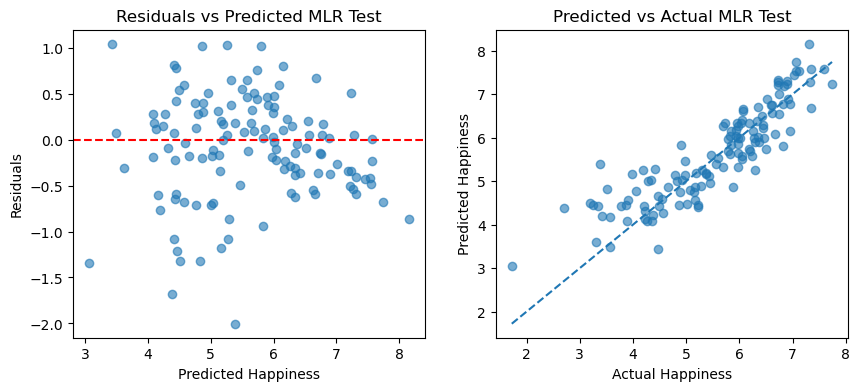

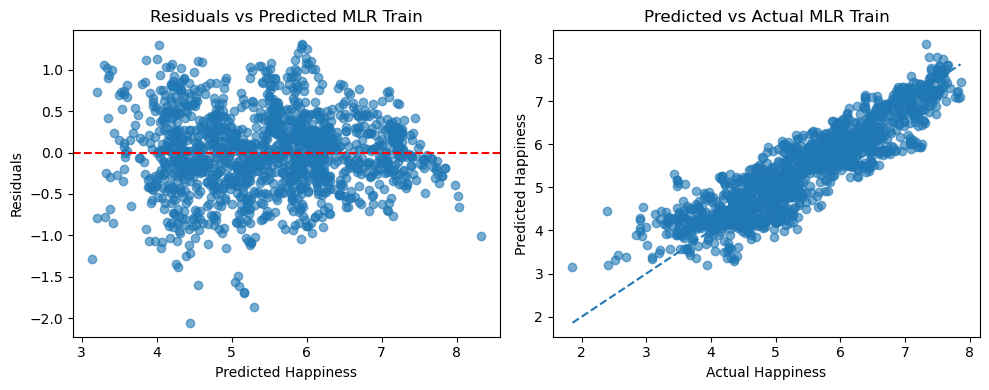

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

model = LinearRegression()
model.fit(X_train_scaled, y_train)



y_pred_train = model.predict(X_train_scaled)

rmse = root_mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)

print('Train Results:')
print('RMSE:', rmse)
print('R²:', r2)
print()

y_pred = model.predict(X_test_scaled)

rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('Test Results:')
print('RMSE:', rmse)
print('R²:', r2)
print()

coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_
})

coef_df = coef_df.sort_values(by="Coefficient", key=abs, ascending=False)

print(coef_df.head(10))

residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted MLR Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual MLR Test")



residuals = y_train - y_pred_train

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_pred_train, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted MLR Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_pred_train, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual MLR Train")

plt.tight_layout()
plt.show()

### Full Feature Set LASSO Regression ###

Creating train/test split from full 500 column dataset

In [15]:
from sklearn.model_selection import train_test_split

# Year based split
train = df[df['year'] <= 2022]
test = df[df['year'] > 2022]


X_train = train.drop(columns = ['Life evaluation (3-year average)', 'year', 'Rank', 'country', 'score_bin'])
y_train = train['Life evaluation (3-year average)']

X_test = test.drop(columns = ['Life evaluation (3-year average)', 'year', 'Rank', 'country', 'score_bin'])
y_test = test['Life evaluation (3-year average)']

print(X_train.shape, X_test.shape)

(1438, 502) (128, 502)


Best alpha: 0.01921736739809019

                                               Feature  Coefficient
405  Price level ratio of PPP conversion factor (GD...     0.160569
460  UHC service coverage sub-index on reproductive...     0.097050
258  Merchandise imports from high-income economies...     0.093367
158  GNI per capita, PPP (constant 2021 internation...     0.092654
251  Merchandise exports to low- and middle-income ...    -0.092353
..                                                 ...          ...
25       Arable land (% of land area) [AG.LND.ARBL.ZS]    -0.003424
98   Exports of goods and services (annual % growth...    -0.002523
93   Export unit value index (2015 = 100) [TX.UVI.M...     0.002286
235  Manufacturing, value added (annual % growth) [...    -0.000661
60   Control of Corruption: Standard Error [CC.STD....     0.000002

[64 rows x 2 columns]

Training RMSE: 0.39666298255122256
Training R²: 0.8762131163095809

Test RMSE: 0.4513550622022199
Test R²: 0.8551408082322532


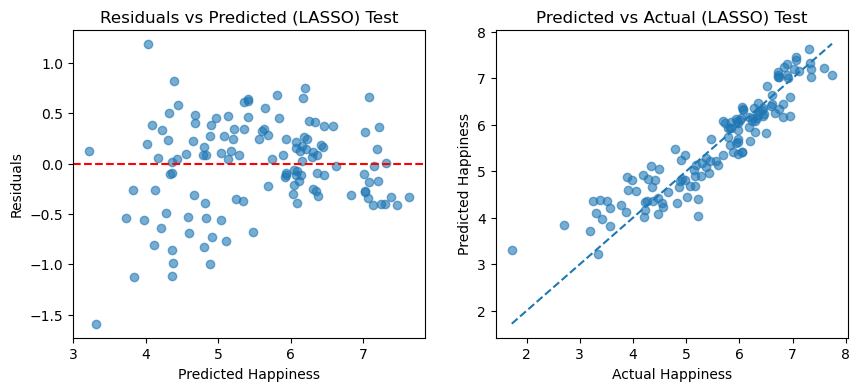

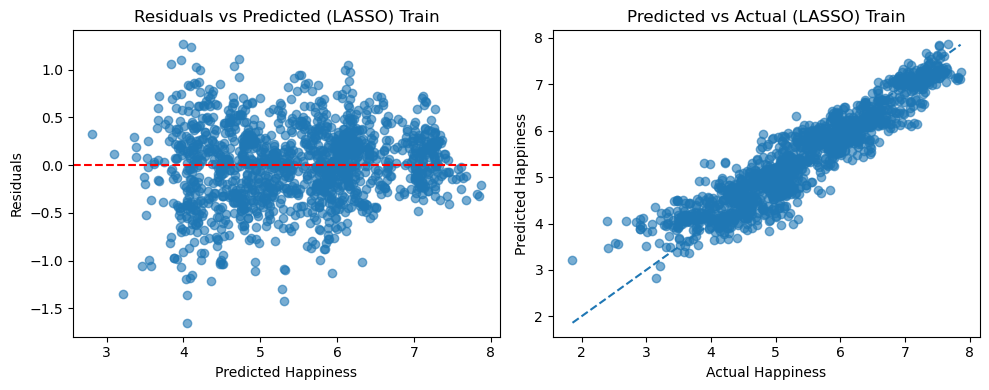

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LassoCV


lasso_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LassoCV(
        cv = 5,
        random_state= 42,
        max_iter = 10000
    ))
])

lasso_pipeline.fit(X_train, y_train)

best_alpha = lasso_pipeline.named_steps['model'].alpha_
print('Best alpha:', best_alpha)
print()

coef = lasso_pipeline.named_steps["model"].coef_

coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coef
})

# Keep only non-zero coefficients
# Storing for feature selection/engineering later 

non_zero = coef_df[coef_df["Coefficient"] != 0]

non_zero = non_zero.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

print(non_zero)
print()

from sklearn.metrics import r2_score, root_mean_squared_error

y_train_pred = lasso_pipeline.predict(X_train)

train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)

y_pred = lasso_pipeline.predict(X_test)

rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print()
print("Test RMSE:", rmse)
print("Test R²:", r2)

residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted (LASSO) Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual (LASSO) Test")



residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted (LASSO) Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual (LASSO) Train")

plt.tight_layout()
plt.show()

### Full Feature Set Ridge Regression ###

Best alpha: 1000.0

Training RMSE: 0.381357636788756
Training R²: 0.885581518690689

Test RMSE: 0.44983497318763394
Test R²: 0.8561148886750846

                                               Feature  Coefficient
405  Price level ratio of PPP conversion factor (GD...     0.038998
251  Merchandise exports to low- and middle-income ...    -0.038043
257  Merchandise imports from economies in the Arab...    -0.037139
460  UHC service coverage sub-index on reproductive...     0.037050
244  Merchandise exports to economies in the Arab W...    -0.035857
385  Population in the largest city (% of urban pop...    -0.034493
393  Preprimary education, duration (years) [SE.PRE...     0.034486
69   Domestic general government health expenditure...     0.033654
261  Merchandise imports from low- and middle-incom...     0.032924
278  Mobile cellular subscriptions (per 100 people)...     0.031477


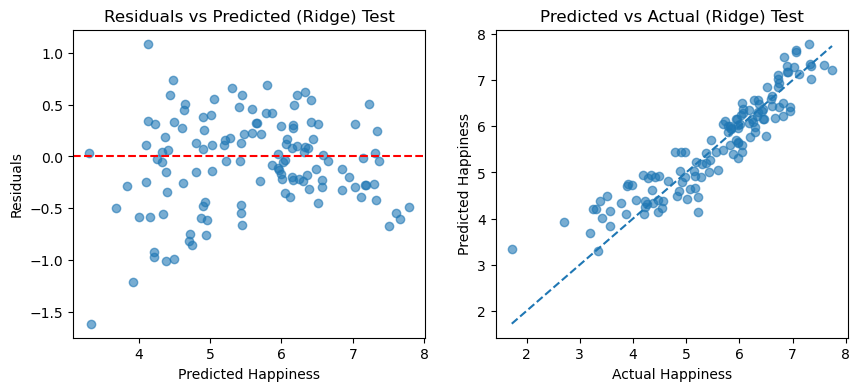

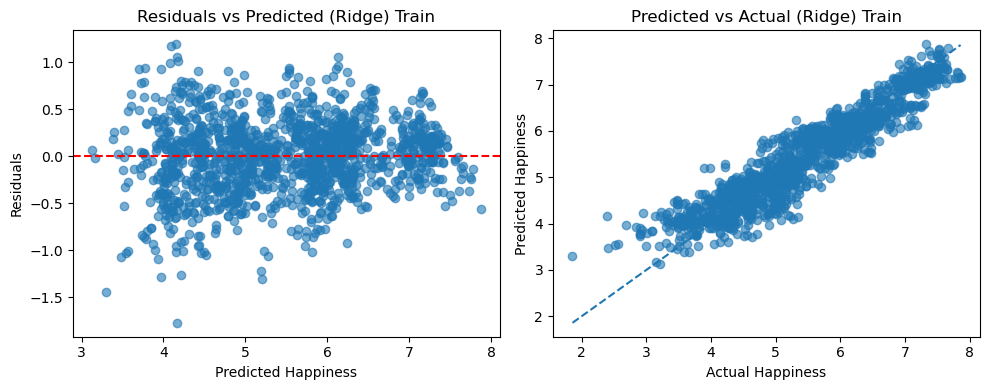

In [17]:
from sklearn.linear_model import RidgeCV

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RidgeCV(
        alphas=[1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100, 1000],
        cv=5
    ))
])

ridge_pipeline.fit(X_train, y_train)

best_alpha = ridge_pipeline.named_steps["model"].alpha_
print("Best alpha:", best_alpha)
print()

y_pred = ridge_pipeline.predict(X_train)
y_pred_test = ridge_pipeline.predict(X_test)

#Train
train_rmse = root_mean_squared_error(y_train, y_pred)
train_r2 = r2_score(y_train, y_pred)

#Test
test_rmse = root_mean_squared_error(y_test, y_pred_test)
test_r2 = r2_score(y_test, y_pred_test)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)
print()

ridge_coef = ridge_pipeline.named_steps["model"].coef_

ridge_coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": ridge_coef
}).sort_values(by="Coefficient", key=abs, ascending=False)

print(ridge_coef_df.head(10))

residuals = y_test - y_pred_test

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_pred_test, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted (Ridge) Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_pred_test, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual (Ridge) Test")


residuals = y_train - y_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted (Ridge) Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual (Ridge) Train")

plt.tight_layout()
plt.show()

### Full Feature Set Gradient Boosting Regressor ###

Training RMSE: 0.192815257114167
Training R²: 0.9707507943934759

Test RMSE: 0.32619128317111235
Test R²: 0.9243421275013459

                                               Feature  Importance
457            UHC service coverage index [SH_UHC_SCI]    0.268894
134  GDP per capita (constant 2015 US$) [NY.GDP.PCA...    0.139104
157  GNI per capita, Atlas method (current US$) [NY...    0.118273
137      GDP per capita (current US$) [NY.GDP.PCAP.CD]    0.063522
62   Current health expenditure per capita (current...    0.039300
286  Mortality rate, under-5, female (per 1,000 liv...    0.037326
494  Gross National Income Per Capita, male (2021 P...    0.026584
282  Mortality rate, infant, female (per 1,000 live...    0.016148
92   Employment to population ratio, ages 15-24, to...    0.015661
261  Merchandise imports from low- and middle-incom...    0.015014


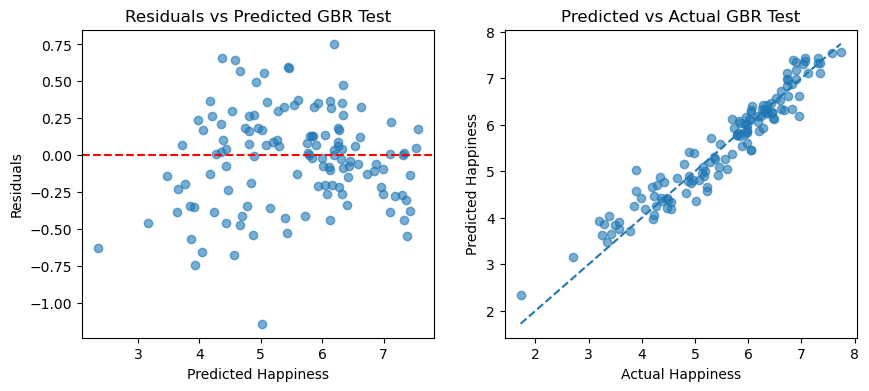

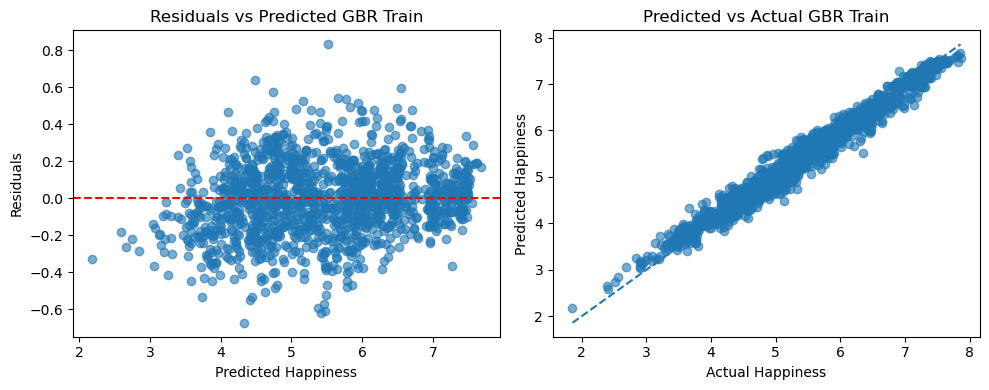

In [18]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(random_state= 42)

gbr.fit(X_train, y_train)

# Train
y_train_pred = gbr.predict(X_train)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = gbr.predict(X_test)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)
print()

imp = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gbr.feature_importances_
}).sort_values("Importance", ascending=False)

print(imp.head(10))

residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted GBR Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual GBR Test")


residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted GBR Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual GBR Train")

plt.tight_layout()
plt.show()

### Full Feature Set AdaBoost ###

Training RMSE: 0.3506211686418691
Training R²: 0.9032819460519755

Test RMSE: 0.40576703905287165
Test R²: 0.8829253268146114

                                               Feature  Importance
457            UHC service coverage index [SH_UHC_SCI]    0.098263
0    Access to clean fuels and technologies for coo...    0.092058
395  Prevalence of anemia among pregnant women (%) ...    0.078308
70   Domestic general government health expenditure...    0.067684
282  Mortality rate, infant, female (per 1,000 live...    0.046409
137      GDP per capita (current US$) [NY.GDP.PCAP.CD]    0.044061
105  External health expenditure (% of current heal...    0.029130
274  Methane (CH4) emissions from Power Industry (E...    0.028124
157  GNI per capita, Atlas method (current US$) [NY...    0.025308
484  Women's share of population ages 15+ living wi...    0.020008


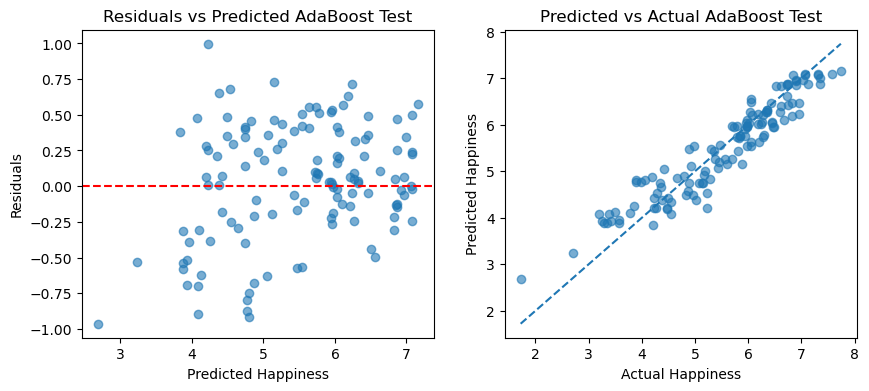

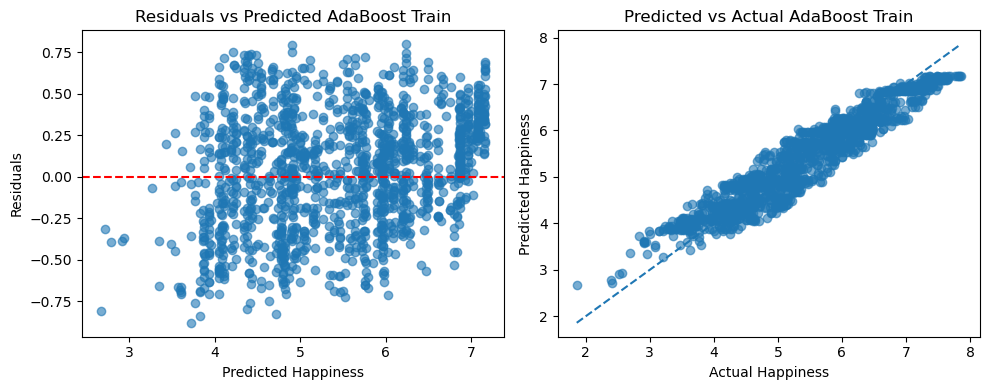

In [19]:
from sklearn.ensemble import AdaBoostRegressor

abr = AdaBoostRegressor(random_state=42)

# Fit
abr.fit(X_train, y_train)

# Train
y_train_pred = abr.predict(X_train)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = abr.predict(X_test)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)
print()

imp = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": abr.feature_importances_
}).sort_values("Importance", ascending=False)

print(imp.head(10))

residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted AdaBoost Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual AdaBoost Test")


residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted AdaBoost Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual AdaBoost Train")

plt.tight_layout()
plt.show()

### Full Feature Set Random Forest ###

Training RMSE: 0.11350327018429816
Training R²: 0.989864433385473

Test RMSE: 0.3192639286871933
Test R²: 0.927521511221307

                                               Feature  Importance
457            UHC service coverage index [SH_UHC_SCI]    0.345328
134  GDP per capita (constant 2015 US$) [NY.GDP.PCA...    0.168892
157  GNI per capita, Atlas method (current US$) [NY...    0.111266
286  Mortality rate, under-5, female (per 1,000 liv...    0.045142
137      GDP per capita (current US$) [NY.GDP.PCAP.CD]    0.027749
261  Merchandise imports from low- and middle-incom...    0.016687
494  Gross National Income Per Capita, male (2021 P...    0.015445
282  Mortality rate, infant, female (per 1,000 live...    0.013149
284  Mortality rate, neonatal (per 1,000 live birth...    0.011285
159  GNI per capita, PPP (current international $) ...    0.009667


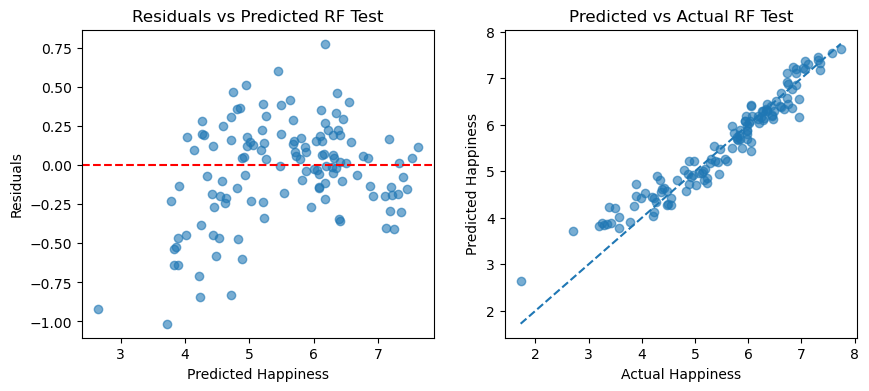

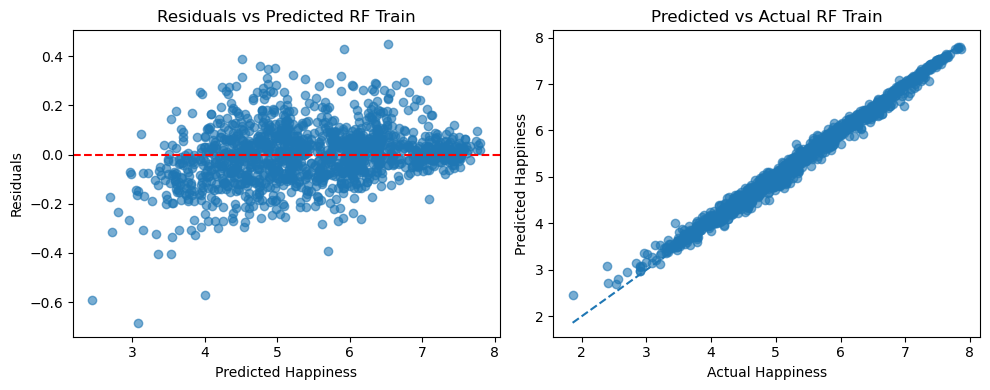

In [20]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(max_depth = 10,
                           random_state=42)

rf.fit(X_train, y_train)

# Train
y_train_pred = rf.predict(X_train)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = rf.predict(X_test)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)
print()

imp = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

print(imp.head(10))

residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted RF Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual RF Test")


residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted RF Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual RF Train")


plt.tight_layout()
plt.show()


### Full Feature Set SVR ###

Training RMSE: 0.20413933620377978
Training R²: 0.9672142834258604

Test RMSE: 0.38008738393463715
Test R²: 0.8972749570764995


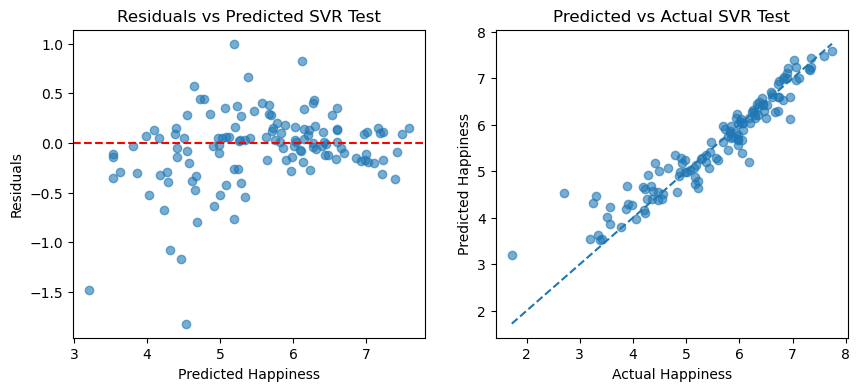

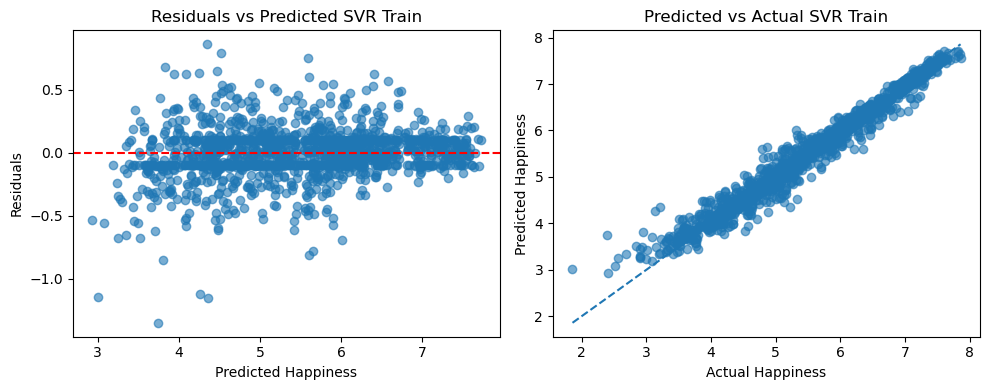

In [21]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler

svr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR())
])

svr_model.fit(X_train, y_train)

# Train
y_train_pred = svr_model.predict(X_train)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = svr_model.predict(X_test)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted SVR Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual SVR Test")


residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted SVR Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual SVR Train")

plt.tight_layout()
plt.show()

### Full Feature Set Decision Tree ###

Training RMSE: 0.18208224424989194
Training R²: 0.9739164632192513

Test RMSE: 0.43878412347027834
Test R²: 0.8630975461271236


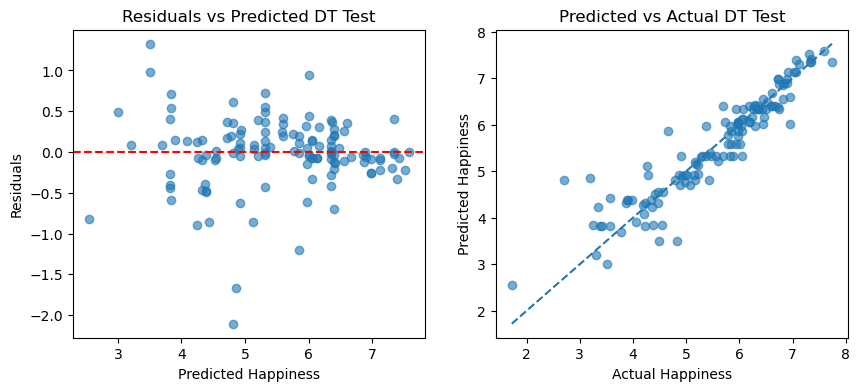

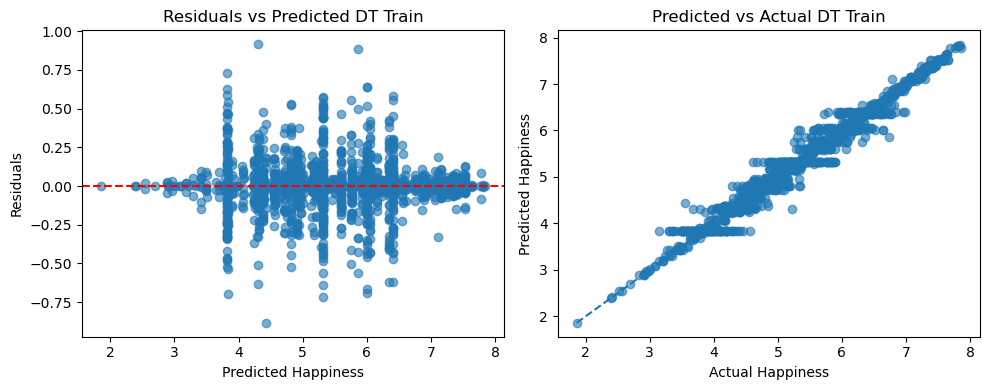

In [22]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth = 8,
                           random_state=42)

dt.fit(X_train, y_train)

# Train
y_train_pred = dt.predict(X_train)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = dt.predict(X_test)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted DT Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual DT Test")


residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted DT Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual DT Train")

plt.tight_layout()
plt.show()

### Full Feature Set XGBoost ###

Training RMSE: 0.12265591376568964
Training R²: 0.9881639097455518

Test RMSE: 0.2793138766410487
Test R²: 0.9445253657730843


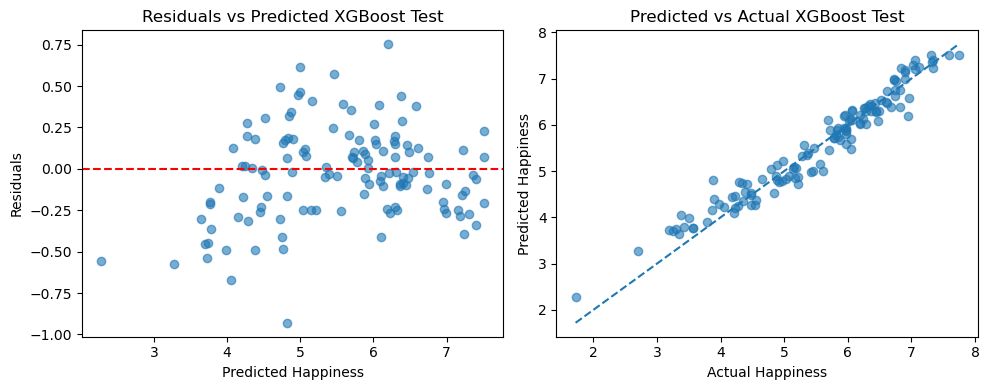

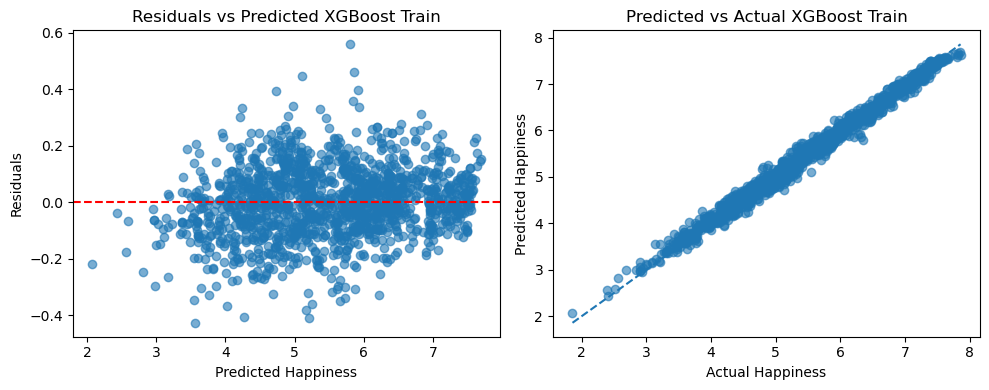

In [23]:
from xgboost import XGBRegressor

import re

def clean_columns(df):
    df = df.copy()
    df.columns = [re.sub(r'[^A-Za-z0-9_]+', '_', col) for col in df.columns]
    return df

X_train_xg = clean_columns(X_train)
X_test_xg = clean_columns(X_test)

xgb = XGBRegressor(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb.fit(X_train_xg, y_train)

# Train
y_train_pred = xgb.predict(X_train_xg)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = xgb.predict(X_test_xg)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

# --- Test plots ---
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted XGBoost Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual XGBoost Test")

plt.tight_layout()
plt.show()

# --- Train plots ---
residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted XGBoost Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual XGBoost Train")

plt.tight_layout()
plt.show()

## Testing Models Using the Features Found From LASSO ##

Running GBR Only Using the 30 most important features found in LASSO 

This produced slightly lower results

In [24]:
selected_features = non_zero["Feature"].tolist()[0:30]

X_train_limited = X_train[selected_features]
X_test_limited = X_test[selected_features]

gbr = GradientBoostingRegressor(random_state= 42)

gbr.fit(X_train_limited, y_train)

# Train
y_train_pred = gbr.predict(X_train_limited)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = gbr.predict(X_test_limited)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

Training RMSE: 0.24044677298307005
Training R²: 0.9545148962867656

Test RMSE: 0.3606510224894617
Test R²: 0.9075123471640172


### Checking scatterplots of the 30 Variables for feature engineering ###

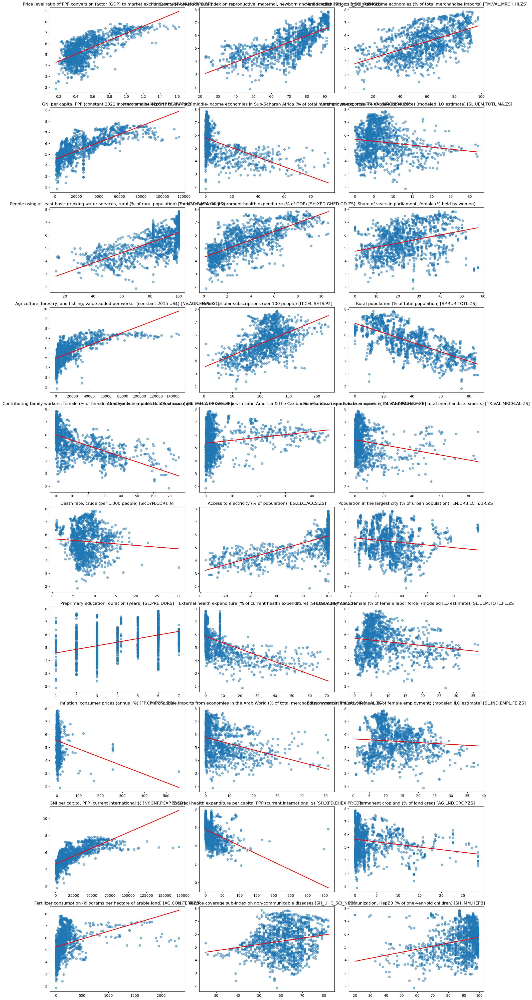

In [25]:
y = df["Life evaluation (3-year average)"]

cols = selected_features
n = len(cols)

ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 4*nrows))
axes = axes.flatten()

for i, col in enumerate(cols):
    ax = axes[i]
    x = X_train_limited[col]
    mask = x.notna() & y.notna()
    x_clean = x[mask]
    y_clean = y[mask]

    m, b = np.polyfit(x_clean, y_clean, 1)
    x_line = np.linspace(x_clean.min(), x_clean.max(), 100)
    y_line = m * x_line + b

    ax.scatter(x_clean, y_clean, alpha=0.5)
    ax.plot(x_line, y_line, color="red", linewidth=2)

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

# Remove unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Applying Transformations to Variables Identified in LASSO ###

In [26]:
X_train_transformed = X_train_limited.copy()
X_test_transformed = X_test_limited.copy()

col1 = 'Agriculture, forestry, and fishing, value added per worker (constant 2015 US$) [NV.AGR.EMPL.KD]'
col2 = 'GNI per capita, PPP (current international $) [NY.GNP.PCAP.PP.CD]'
col3 = 'Merchandise imports from low- and middle-income economies in Latin America & the Caribbean (% of total merchandise imports) [TM.VAL.MRCH.R3.ZS]'
col4 = 'Price level ratio of PPP conversion factor (GDP) to market exchange rate [PA.NUS.PPPC.RF]'
col5 = 'GNI per capita, PPP (constant 2021 international $) [NY.GNP.PCAP.PP.KD]'

cols = [col1, col2, col3, col4, col5]

# Apply log transformation
for col in cols:
    X_train_transformed.loc[:, col] = np.log(X_train_transformed[col])
    X_test_transformed.loc[:, col] = np.log(X_test_transformed[col])

# Rename columns to include "Log"
rename_dict = {col: f"Log {col}" for col in cols}

X_train_transformed.rename(columns=rename_dict, inplace=True)
X_test_transformed.rename(columns=rename_dict, inplace=True)

### LASSO Results on Limited Features Prior to Engineering ###

In [27]:
lasso_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LassoCV(
        cv = 5,
        random_state= 42,
        max_iter = 10000
    ))
])

lasso_pipeline.fit(X_train_limited, y_train)

best_alpha = lasso_pipeline.named_steps['model'].alpha_
print('Best alpha:', best_alpha)
print()

y_train_pred = lasso_pipeline.predict(X_train_limited)

train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()

y_pred = lasso_pipeline.predict(X_test_limited)

rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Test RMSE:", rmse)
print("Test R²:", r2)

Best alpha: 0.0024208691006630577

Training RMSE: 0.4051760025529979
Training R²: 0.8708427723146761

Test RMSE: 0.46421714091856636
Test R²: 0.8467671894650495


### LASSO Results on Limited Features Post Engineering ###
Improvements in RMSE and R²

In [28]:
lasso_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LassoCV(
        cv = 5,
        random_state= 42,
        max_iter = 10000
    ))
])

lasso_pipeline.fit(X_train_transformed, y_train)

best_alpha = lasso_pipeline.named_steps['model'].alpha_
print('Best alpha:', best_alpha)
print()

y_train_pred = lasso_pipeline.predict(X_train_transformed)

train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()

y_pred = lasso_pipeline.predict(X_test_transformed)

rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Test RMSE:", rmse)
print("Test R²:", r2)



Best alpha: 0.004250355966316356

Training RMSE: 0.4106775754415601
Training R²: 0.8673115067666947

Test RMSE: 0.4436220666332326
Test R²: 0.8600619867640624


### Creating a Final Training and Test Set Using All Variables From LASSO With the Engineered Features ###

In [29]:
selected_features = non_zero["Feature"].tolist()

X_train_final = X_train[selected_features].copy()
X_test_final = X_test[selected_features].copy()

cols = [col1, col2, col3, col4, col5]
log_cols = [f"Log {c}" for c in cols]

# 1) Drop the original (un-logged) versions if they exist in final
X_train_final.drop(columns=[c for c in cols if c in X_train_final.columns], inplace=True)
X_test_final.drop(columns=[c for c in cols if c in X_test_final.columns], inplace=True)

# 2) Add the logged versions from the transformed frames
# (X_train_transformed/X_test_transformed have the renamed log columns)
X_train_final[log_cols] = X_train_transformed[log_cols]
X_test_final[log_cols] = X_test_transformed[log_cols]


In [30]:
print(X_train_final.columns)

Index(['UHC service coverage sub-index on reproductive, maternal, newborn and child health [SH_UHC_SCI_RMNCH]',
       'Merchandise imports from high-income economies (% of total merchandise imports) [TM.VAL.MRCH.HI.ZS]',
       'Merchandise exports to low- and middle-income economies in Sub-Saharan Africa (% of total merchandise exports) [TX.VAL.MRCH.R6.ZS]',
       'Unemployment, male (% of male labor force) (modeled ILO estimate) [SL.UEM.TOTL.MA.ZS]',
       'People using at least basic drinking water services, rural (% of rural population) [SH.H2O.BASW.RU.ZS]',
       'Domestic general government health expenditure (% of GDP) [SH.XPD.GHED.GD.ZS]',
       'Share of seats in parliament, female (% held by women)',
       'Mobile cellular subscriptions (per 100 people) [IT.CEL.SETS.P2]',
       'Rural population (% of total population) [SP.RUR.TOTL.ZS]',
       'Contributing family workers, female (% of female employment) (modeled ILO estimate) [SL.FAM.WORK.FE.ZS]',
       'Merchandise

### LASSO Results Using Finalized List of 64 Features ###

Best alpha: 0.00524003749454125

Training RMSE: 0.37362818452314656
Training R²: 0.8901726403242223

Test RMSE: 0.43302671978845675
Test R²: 0.8666666432802356



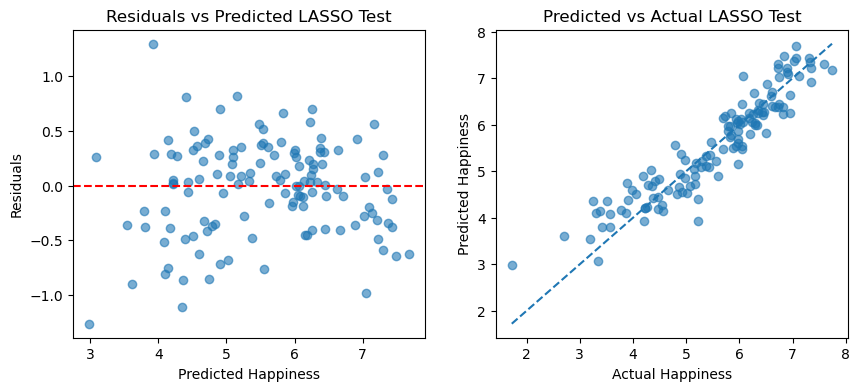

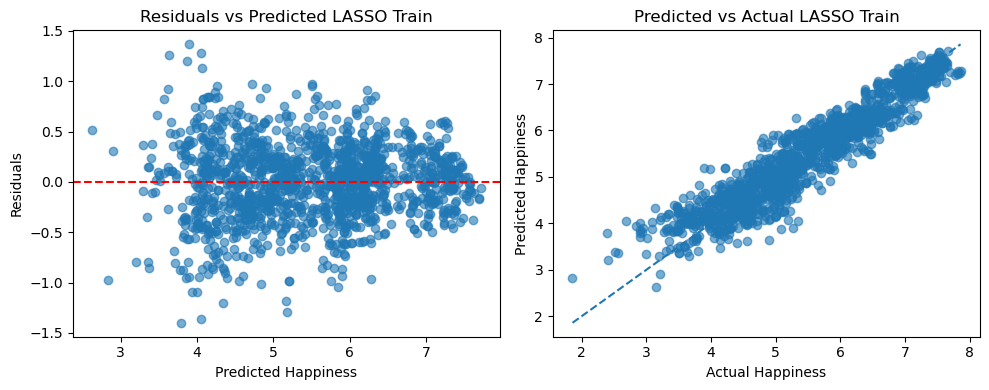

In [31]:
lasso_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LassoCV(
        cv = 5,
        random_state= 42,
        max_iter = 10000
    ))
])

lasso_pipeline.fit(X_train_final, y_train)

best_alpha = lasso_pipeline.named_steps['model'].alpha_
print('Best alpha:', best_alpha)
print()

y_train_pred = lasso_pipeline.predict(X_train_final)

train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()

y_test_pred = lasso_pipeline.predict(X_test_final)

rmse = root_mean_squared_error(y_test, y_test_pred)
r2 = r2_score(y_test, y_test_pred)

print("Test RMSE:", rmse)
print("Test R²:", r2)
print()

residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted LASSO Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual LASSO Test")



residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted LASSO Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual LASSO Train")

plt.tight_layout()
plt.show()


### Final GradientBoosted Regressor Results Using 64 Finalized Features ###

Grid Search to Find Best Parameters

In [32]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [200, 400, 800],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_leaf": [1, 2, 4],
    "subsample": [0.8, 1.0],
}

grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train_final, y_train)

best_gbr = grid.best_estimator_
print("Best params:", grid.best_params_)
print("Best CV RMSE:", -grid.best_score_)

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Best params: {'learning_rate': 0.03, 'max_depth': 4, 'min_samples_leaf': 2, 'n_estimators': 800, 'subsample': 0.8}
Best CV RMSE: 0.4910667214733895


Results

Training RMSE: 0.07270822717705751
Training R²: 0.9958409092687457

Test RMSE: 0.2818135369631102
Test R²: 0.9435280058673586

                                              Feature  Importance
50  GNI per capita, Atlas method (current US$) [NY...    0.556412
12  Access to electricity (% of population) [EG.EL...    0.058697
60  Log GNI per capita, PPP (current international...    0.034000
5   Domestic general government health expenditure...    0.021445
59  Log Agriculture, forestry, and fishing, value ...    0.021200
61  Log Merchandise imports from low- and middle-i...    0.019960
34  Employment to population ratio, ages 15-24, ma...    0.018165
0   UHC service coverage sub-index on reproductive...    0.017131
48  Access to clean fuels and technologies for coo...    0.015577
23  UHC service coverage sub-index on non-communic...    0.011994


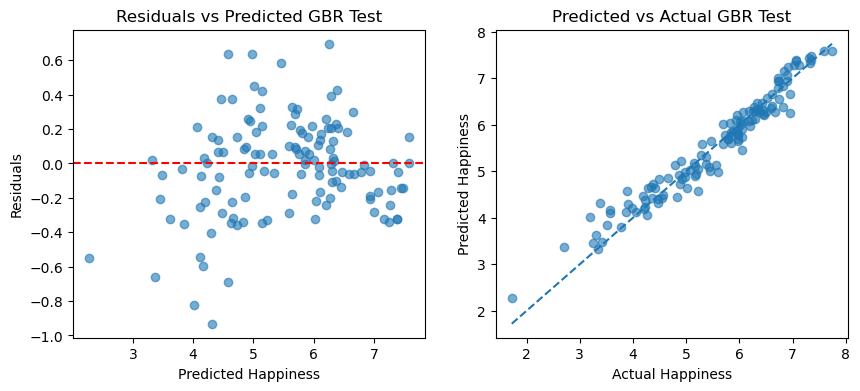

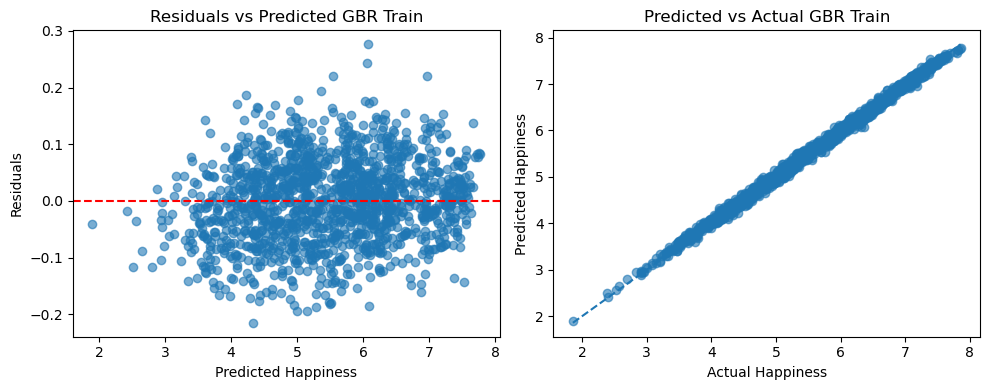

In [33]:
gbr = GradientBoostingRegressor(
    n_estimators = 800,
    learning_rate = .03,
    max_depth = 4,
    min_samples_leaf = 2,
    subsample = 0.8,
    random_state= 42)

gbr.fit(X_train_final, y_train)

# Train
y_train_pred = gbr.predict(X_train_final)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = gbr.predict(X_test_final)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)
print()

imp = pd.DataFrame({
    "Feature": X_train_final.columns,
    "Importance": gbr.feature_importances_
}).sort_values("Importance", ascending=False)

print(imp.head(10))

residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted GBR Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual GBR Test")


residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted GBR Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual GBR Train")

plt.tight_layout()
plt.show()

### Final MultiLinear Regression Results Using Finalized 64 Features ###

Train Results:
RMSE: 0.4166122129154908
R²: 0.8634488764759559

Test Results:
RMSE: 0.48611265652336444
R²: 0.8319713726511677



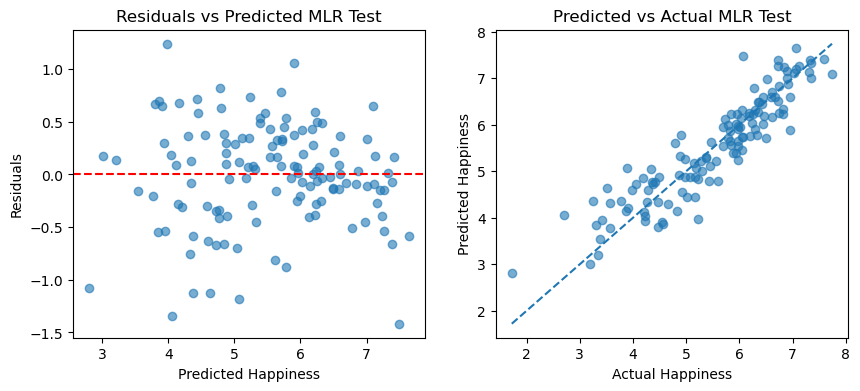

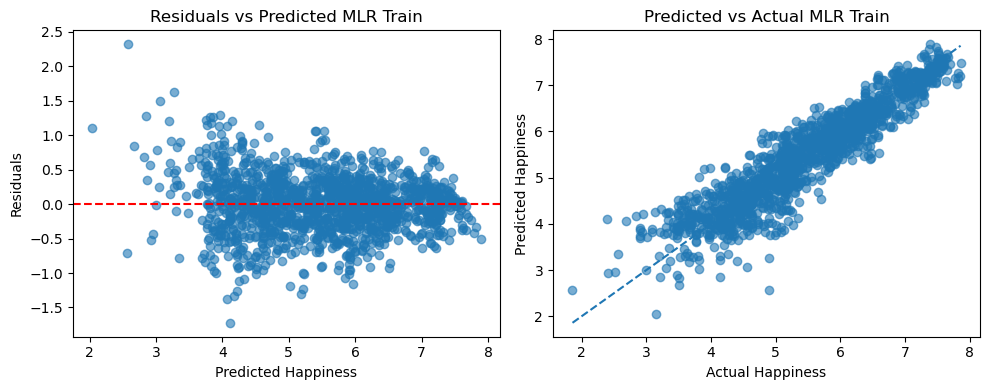

In [34]:
model = LinearRegression()
model.fit(X_train_final, y_train)


y_train_pred = model.predict(X_train_final)

rmse = root_mean_squared_error(y_train, y_train_pred)
r2 = r2_score(y_train, y_train_pred)

print('Train Results:')
print('RMSE:', rmse)
print('R²:', r2)
print()

y_pred = model.predict(X_test_final)

rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('Test Results:')
print('RMSE:', rmse)
print('R²:', r2)
print()

residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted MLR Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual MLR Test")


residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted MLR Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual MLR Train")

plt.tight_layout()
plt.show()

### Final Ridge Results Using Finalized 64 Features ###

Best alpha: 1000.0

Training RMSE: 0.405744098356022
Training R²: 0.8704803366472122

Test RMSE: 0.45040699737469625
Test R²: 0.8557487184125057


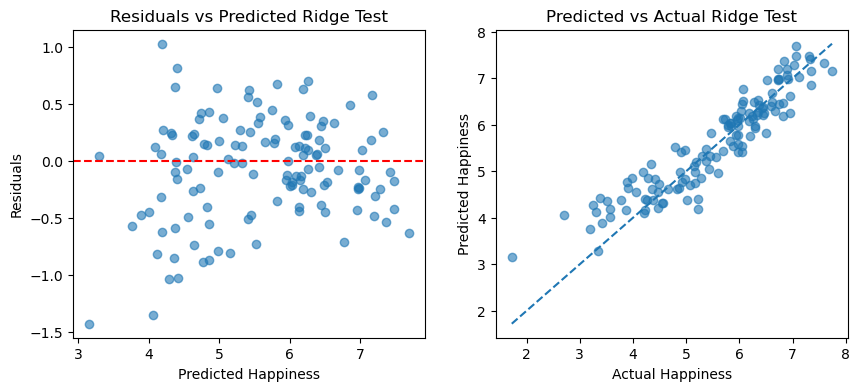

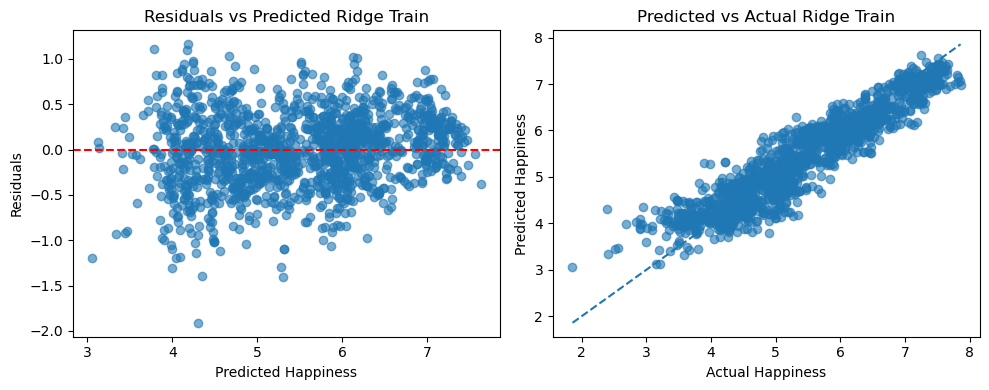

In [35]:
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RidgeCV(
        alphas=[1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100, 1000],
        cv=5
    ))
])

ridge_pipeline.fit(X_train_final, y_train)

best_alpha = ridge_pipeline.named_steps["model"].alpha_
print("Best alpha:", best_alpha)
print()

y_pred = ridge_pipeline.predict(X_train_final)
y_pred_test = ridge_pipeline.predict(X_test_final)

#Train
train_rmse = root_mean_squared_error(y_train, y_pred)
train_r2 = r2_score(y_train, y_pred)

#Test
test_rmse = root_mean_squared_error(y_test, y_pred_test)
test_r2 = r2_score(y_test, y_pred_test)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

residuals = y_test - y_pred_test

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_pred_test, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted Ridge Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_pred_test, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual Ridge Test")


residuals = y_train - y_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted Ridge Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual Ridge Train")

plt.tight_layout()
plt.show()

### Final AdaBoost Regression Using 64 Finalized Features ###

Training RMSE: 0.38917384033591473
Training R²: 0.8808432735143452

Test RMSE: 0.46466338356641473
Test R²: 0.8464724486001843


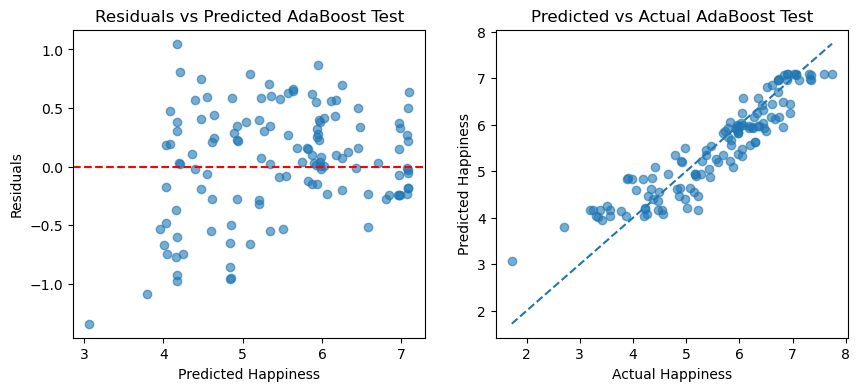

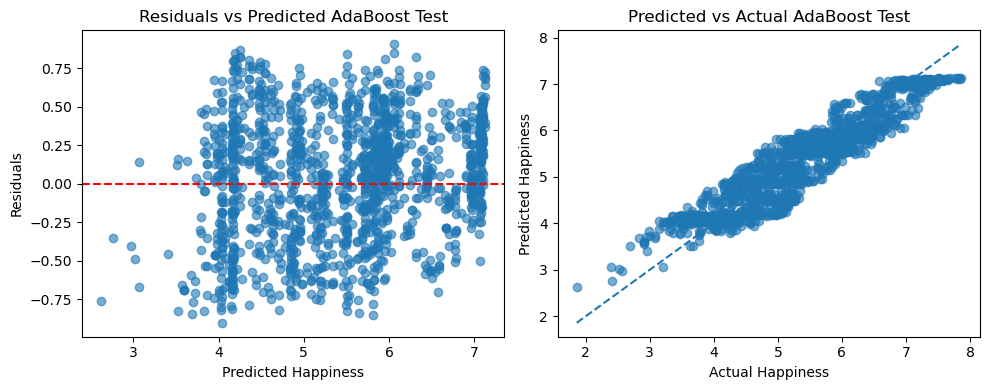

In [36]:
from sklearn.ensemble import AdaBoostRegressor

abr = AdaBoostRegressor(random_state=42)

# Fit
abr.fit(X_train_final, y_train)

# Train
y_train_pred = abr.predict(X_train_final)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = abr.predict(X_test_final)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted AdaBoost Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual AdaBoost Test" )


residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted AdaBoost Test")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual AdaBoost Test")

plt.tight_layout()
plt.show()

### Final Random Forest Regressor Using 64 Finalized Features ###

Grid Search to Find Best Parameters

In [37]:
from sklearn.model_selection import RandomizedSearchCV

rf = RandomForestRegressor(random_state=42)

param_dist = {
    "n_estimators": [100, 200, 300, 500, 800],
    "max_depth": [None, 5, 10, 15, 20, 30],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 2, 4, 6],
    "max_features": ["sqrt", "log2", None]
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=40,
    scoring="neg_root_mean_squared_error",
    cv=5,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train_final, y_train)

print("Best parameters:")
print(random_search.best_params_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best parameters:
{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 30}


Results

Training RMSE: 0.11598847005144369
Training R²: 0.9894157296711228

Test RMSE: 0.3265386846332954
Test R²: 0.9241808868229644


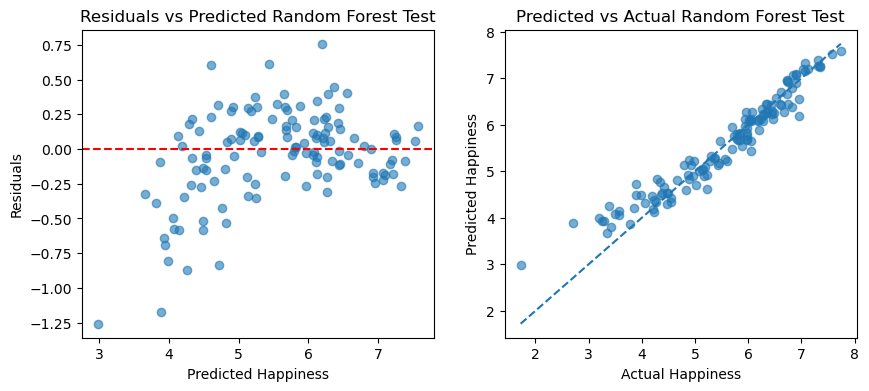

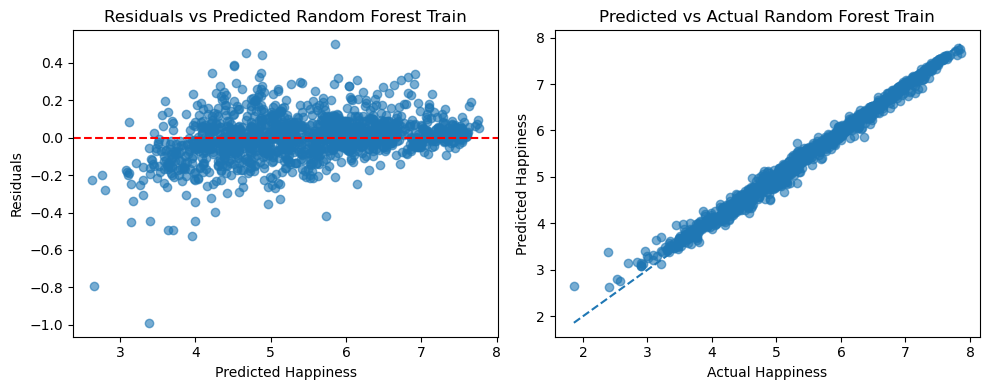

In [38]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42,
                           n_estimators=500,
                           min_samples_split=2,
                           min_samples_leaf = 2,
                           max_features= 'sqrt',
                           max_depth= 30)

rf.fit(X_train_final, y_train)

# Train
y_train_pred = rf.predict(X_train_final)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = rf.predict(X_test_final)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted Random Forest Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual Random Forest Test")


residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted Random Forest Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual Random Forest Train")

plt.tight_layout()
plt.show()

### Final SVR Using 64 Finalized Features ###

Training RMSE: 0.19686856121199062
Training R²: 0.9695081328929387

Test RMSE: 0.39784195308017367
Test R²: 0.887453866649538


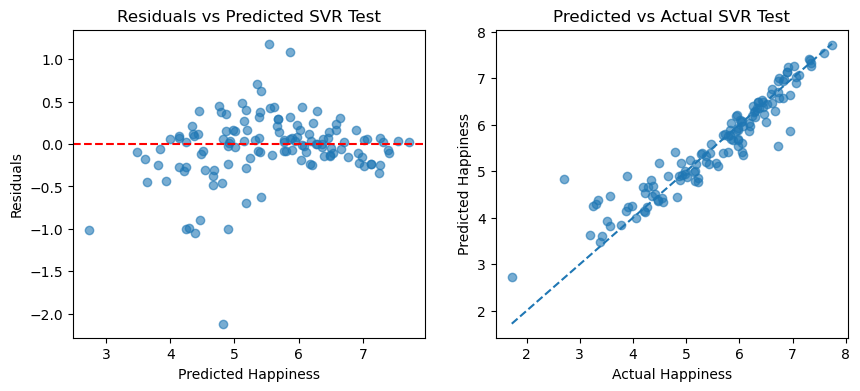

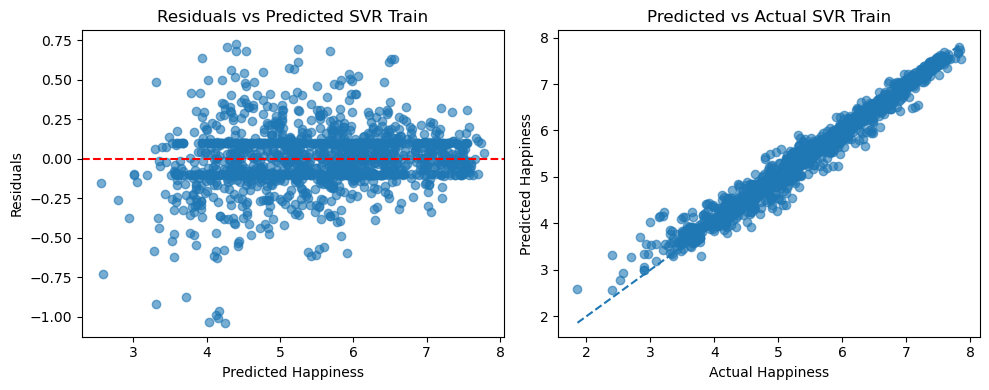

In [39]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler

svr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR())
])

svr_model.fit(X_train_final, y_train)

# Train
y_train_pred = svr_model.predict(X_train_final)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = svr_model.predict(X_test_final)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted SVR Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual SVR Test")


residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted SVR Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual SVR Train")

plt.tight_layout()
plt.show()

### Final Descision Tree Regressor Using 64 Finalized Features ###

Grid Search to Find Best Parameters

In [40]:
param_grid = {
    "max_depth": [3,5,8,12,15],
    "min_samples_leaf": [1,3,5,10],
    "min_samples_split": [2,10,20,40]
}

grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

grid.fit(X_train_final, y_train)

best_dt = grid.best_estimator_

Results

Training RMSE: 0.1258111795876889
Training R²: 0.9875471214605208

Test RMSE: 0.42937788864315024
Test R²: 0.8689042010520058


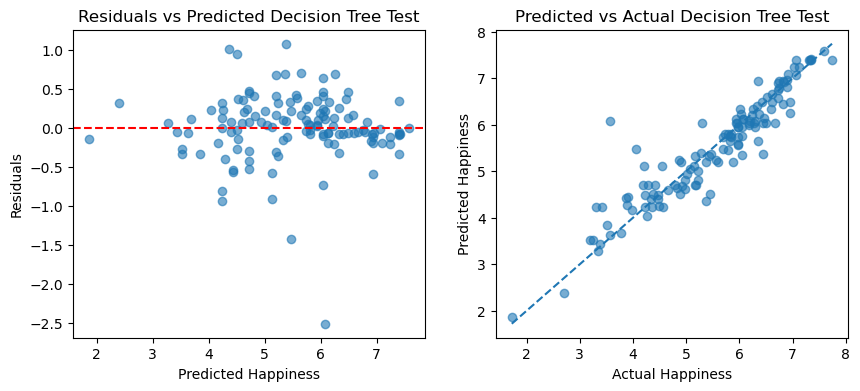

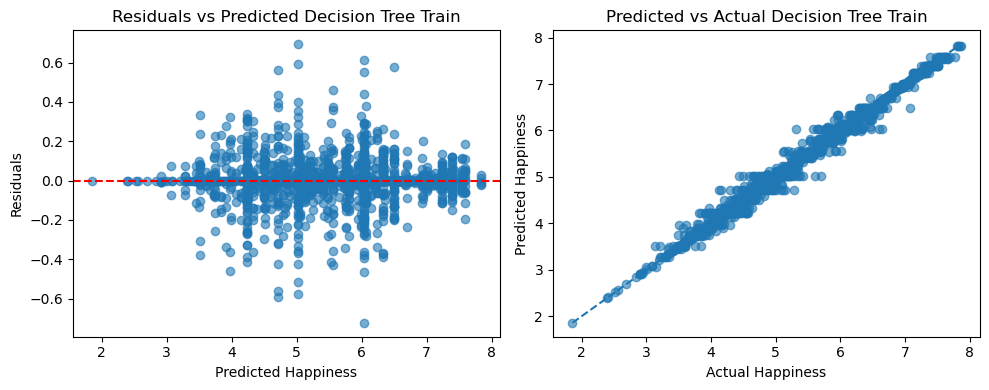

In [41]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth = 10,
                           random_state=42)

dt.fit(X_train_final, y_train)

# Train
y_train_pred = dt.predict(X_train_final)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = dt.predict(X_test_final)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted Decision Tree Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual Decision Tree Test")


residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted Decision Tree Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual Decision Tree Train")

plt.tight_layout()
plt.show()

### Final XGBoost Regressor Using 64 Finalized Features ###

Using Randomized Search to Find Best Parameters

In [42]:
from sklearn.model_selection import RandomizedSearchCV

import re

def clean_columns(df):
    df = df.copy()
    df.columns = [re.sub(r'[^A-Za-z0-9_]+', '_', col) for col in df.columns]
    return df

X_train_xg = clean_columns(X_train_final)
X_test_xg = clean_columns(X_test_final)

param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "gamma": [0, 0.1, 0.3, 0.5],
    "min_child_weight": [1, 3, 5]
}

xgb = XGBRegressor(
    random_state=42,
    objective="reg:squarederror"
)

random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=5,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train_xg, y_train)

print("Best parameters:")
print(random_search.best_params_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best parameters:
{'subsample': 0.8, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.6}


Results

Training RMSE: 0.07979358693732348
Training R²: 0.9949908128235117

Test RMSE: 0.2838746941169599
Test R²: 0.9426989235131649


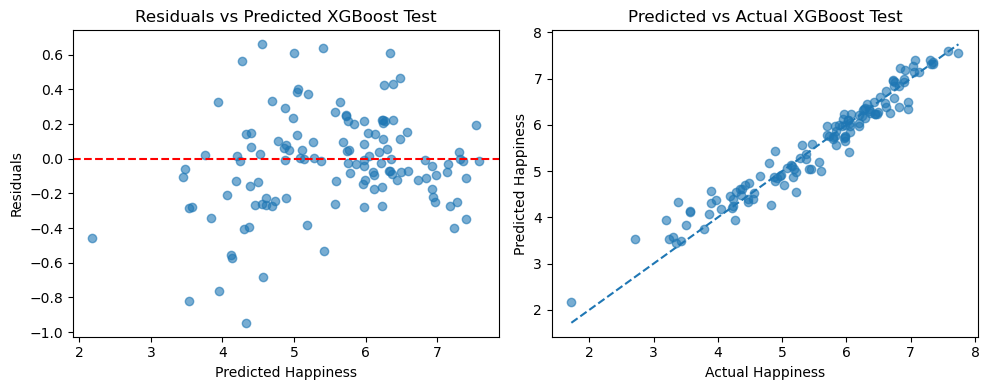

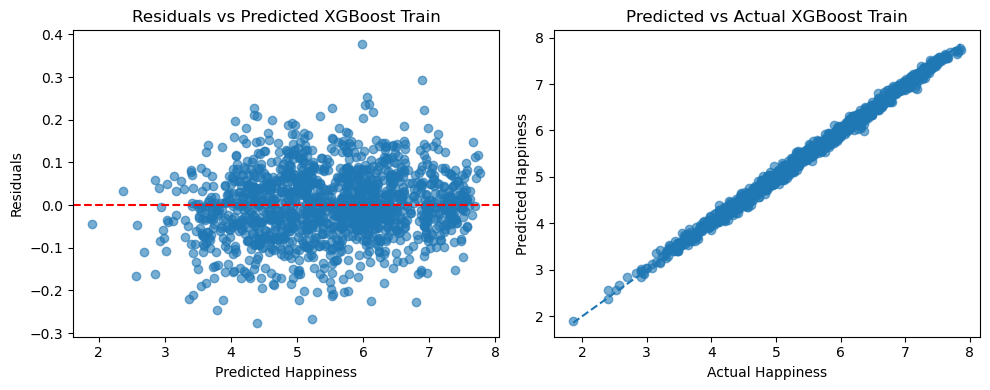

In [43]:
from xgboost import XGBRegressor

import re

def clean_columns(df):
    df = df.copy()
    df.columns = [re.sub(r'[^A-Za-z0-9_]+', '_', col) for col in df.columns]
    return df

X_train_xg = clean_columns(X_train_final)
X_test_xg = clean_columns(X_test_final)

xgb = XGBRegressor(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.6,
    min_child_weight = 5,
    gamma = 0,
    random_state=42
)

xgb.fit(X_train_xg, y_train)

# Train
y_train_pred = xgb.predict(X_train_xg)
train_rmse = root_mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Test
y_test_pred = xgb.predict(X_test_xg)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training RMSE:", train_rmse)
print("Training R²:", train_r2)
print()
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

# --- Test plots ---
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Residuals vs Predicted
axes[0].scatter(y_test_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted XGBoost Test")

# Predicted vs Actual
axes[1].scatter(y_test, y_test_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual XGBoost Test")

plt.tight_layout()
plt.show()

# --- Train plots ---
residuals = y_train - y_train_pred

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Residuals vs Predicted
axes[0].scatter(y_train_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted XGBoost Train")

# Predicted vs Actual
axes[1].scatter(y_train, y_train_pred, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual XGBoost Train")

plt.tight_layout()
plt.show()

## Creating an Ensemble Model Using the Two Best Models ##
### Gradient Boosting Regressor and XGBoost Regressor ###

Test Results:
Stacked RMSE: 0.2767684972461175
Stacked R^2: 0.9455318363331661

Train Results:
Stacked RMSE: 0.07588298996053272
Stacked R^2: 0.9954697710283593


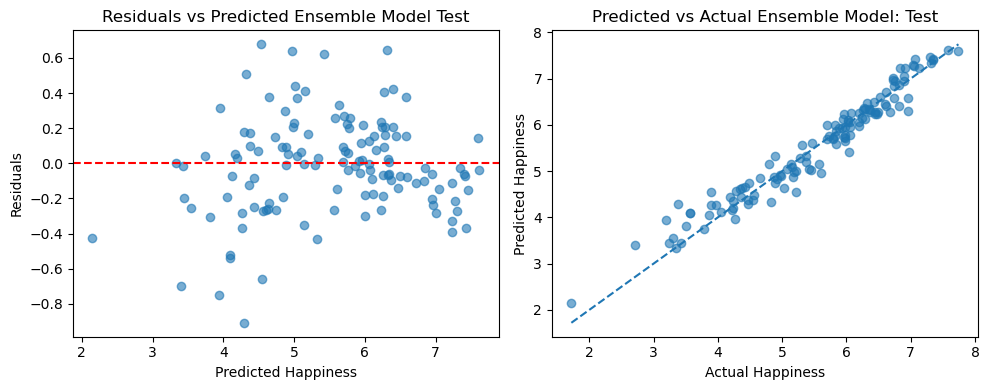

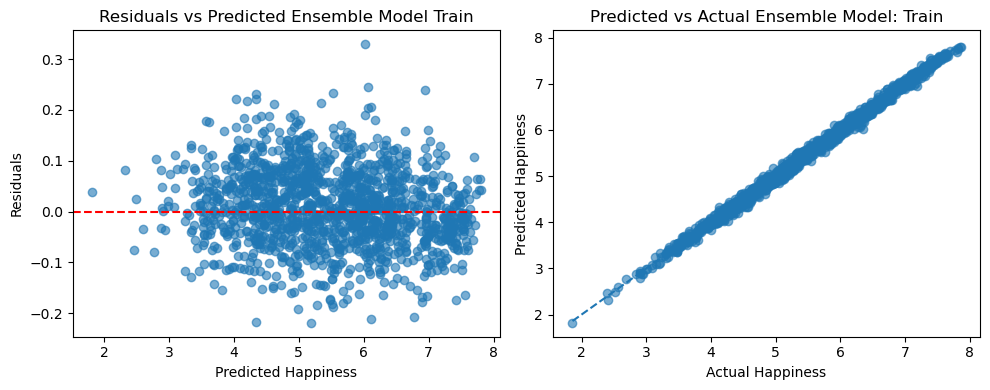

In [44]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression

best_gbr = GradientBoostingRegressor(
    n_estimators = 800,
    learning_rate = .03,
    max_depth = 4,
    min_samples_leaf = 2,
    subsample = 0.8,
    random_state= 42)

best_xgb = XGBRegressor(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.6,
    min_child_weight = 5,
    gamma = 0,
    random_state=42
)

stack_model = StackingRegressor(
    estimators=[
        ("GBR", best_gbr),
        ("XGB", best_xgb)
    ]
)

stack_model.fit(X_train_xg, y_train)

stack_pred = stack_model.predict(X_test_xg)

stack_rmse = root_mean_squared_error(y_test, stack_pred)
stack_r2 = r2_score(y_test, stack_pred)

print("Test Results:")
print("Stacked RMSE:", stack_rmse)
print("Stacked R^2:", stack_r2)
print()

pred_train = stack_model.predict(X_train_xg)

train_rmse = root_mean_squared_error(y_train, pred_train)
train_r2 = r2_score(y_train, pred_train)

print("Train Results:")
print("Stacked RMSE:", train_rmse)
print("Stacked R^2:", train_r2)



residuals = y_test - stack_pred

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Residuals vs Predicted
axes[0].scatter(stack_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted Ensemble Model Test")

# Predicted vs Actual
axes[1].scatter(y_test, stack_pred, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual Ensemble Model: Test")

plt.tight_layout()
plt.show()

# --- Train plots ---
residuals = y_train - pred_train

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Residuals vs Predicted
axes[0].scatter(pred_train, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Happiness")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted Ensemble Model Train")

# Predicted vs Actual
axes[1].scatter(y_train, pred_train, alpha=0.6)
axes[1].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    linestyle='--'
)
axes[1].set_xlabel("Actual Happiness")
axes[1].set_ylabel("Predicted Happiness")
axes[1].set_title("Predicted vs Actual Ensemble Model: Train")

plt.tight_layout()
plt.show()


In [45]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    stack_model,
    X_test_xg,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": X_train_xg.columns,
    "Importance": perm.importances_mean
}).sort_values(by="Importance", ascending=False)

print(perm_df.head(10))

                                              Feature  Importance
50  GNI_per_capita_Atlas_method_current_US_NY_GNP_...    0.344495
5   Domestic_general_government_health_expenditure...    0.018032
12  Access_to_electricity_of_population_EG_ELC_ACC...    0.016697
25         Consumer_price_index_2010_100_FP_CPI_TOTL_    0.013661
0   UHC_service_coverage_sub_index_on_reproductive...    0.012713
48  Access_to_clean_fuels_and_technologies_for_coo...    0.011823
60  Log_GNI_per_capita_PPP_current_international_N...    0.010178
34  Employment_to_population_ratio_ages_15_24_male...    0.008923
61  Log_Merchandise_imports_from_low_and_middle_in...    0.008743
15  External_health_expenditure_of_current_health_...    0.008141
